# Global Codex Check

This notebook has two independent parts:

1. **Build the saved NetCDFs** — documents the one-time consolidation and global
   averaging. Completed matching products are reused.
2. **Load saved NetCDFs and analyse — START HERE for normal use.** Start at that
   section's first code cell in a fresh kernel, then run the cells below it.
   It opens two files directly; it never opens the partition inventory or runs
   profile processing/global aggregation.

Saved products are under `/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/`:

- `global_profiles.nc`: all **1,117,885 individual profiles**, including the
  repaired batch, all 48 data variables and three coordinates.
- `global_binned_3deg.nc`: one xarray dataset containing both the pressure and
  neutral-density grids. Variable suffixes `_pressure` and `_density` distinguish
  the two vertical grids without creating a pressure × density cross-product.

The analysis includes the global thermal/salinity production and fraction maps,
coverage checks, and the NATRE bitwise comparison against Espe's original file.
Both NetCDFs open lazily; select a region or level before loading profile arrays.

**Measured in a fresh kernel:** opening both saved files took about 8 seconds; the six global maps were ready by 13 seconds; all of Part 2, including the NATRE bitwise proof and profile plots, finished in about 43 seconds on this server.


## Part 1 — Build the saved NetCDFs (one-time preparation)

The functions below show how the two analysis files are made. The profile export
reads the complete recovered manifest in bounded batches and writes one chunked,
uncompressed NetCDF4 file. All numerical variables retain their original
precision; each written block is checked byte-for-byte, and string fields are
checked exactly. Different source-file time origins are converted to exact
integer nanoseconds, preserving decoded timestamps. The file is reopened to
verify the first, last and repaired partitions. Source partitions are preserved.

The averages are computed from those same saved profile partitions without
rerunning Argo processing. Their two grids are then merged into one NetCDF and
every saved array is checked against the separate source grids. Run reports are
saved alongside the products. Matching completed files are reused; if changing
build settings, choose new output filenames and update the analysis paths.


In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display

build_code_dir = next(p for p in (Path.cwd(), Path.cwd() / "notebooks/espe_code")
                      if (p / "global_netcdf.py").is_file())
if str(build_code_dir) not in sys.path:
    sys.path.insert(0, str(build_code_dir))
from global_netcdf import consolidate_profiles, save_binned_grids
from global_binned_means import compute_global_binned_means

SOURCE_MANIFEST = Path("/swot/SUM05/amf2288/argo_mixing/global_repair_20261113/manifest.json")
PRODUCT_DIR = Path("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116")
PROFILE_NETCDF = PRODUCT_DIR / "global_profiles.nc"
BINNED_NETCDF = PRODUCT_DIR / "global_binned_3deg.nc"


In [2]:
profile_export_report = consolidate_profiles(
    SOURCE_MANIFEST, PROFILE_NETCDF, workers=4, files_per_task=8,
)
display({k: profile_export_report[k] for k in [
    "status", "output_file", "profiles", "source_files",
    "variables_including_coordinates", "verified_variable_blocks",
    "file_bytes", "elapsed_seconds",
]})


Reusing complete profile NetCDF: /swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_profiles.nc


{'status': 'complete',
 'output_file': '/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_profiles.nc',
 'profiles': 1117885,
 'source_files': 25686,
 'variables_including_coordinates': 51,
 'verified_variable_blocks': 157339,
 'file_bytes': 148855297151,
 'elapsed_seconds': 758.5304630459286}

### Binning definitions

Use all accepted profiles and all available dates. Cells are **3° × 3°**, anchored
at −90° latitude / −180° longitude, with dateline wrapping. Vertical bins are
lower-inclusive and upper-exclusive, covering the observed finite range.

- Editable default widths: **50 dbar** pressure and **0.05 kg/m³** neutral density.
- Mixing values are saved on `Zfs`. Their pressure coordinate is mean saved
  `pressure` where `abs(Zmeas − Zfs) < 25 m`, matching the local support of the
  stored `gamman_fs`. Depth in metres is not treated as pressure in dbar.
  Neutral-density binning uses `gamman_fs` directly.
- Every finite saved `Zfs` observation has equal weight. Profiles can contribute
  several observations to a bin; these are observation-weighted means, not
  equal-profile or equal-float means. All dates are pooled; no bootstrap or
  additional outlier filtering is applied.
- Saved terms are `Krho`, `epsilon`, `chi`, `Pdia`, `chiS` and **PSdia = PdiaS**.
  Residuals **Piso = chi − Pdia** and **PSiso = chiS − PdiaS** are formed per
  observation, with paired finite inputs, before averaging. Negatives are retained.
- Every metric has a mean, sum and `*_count`. `observation_count` counts valid
  coordinates regardless of metric availability; `profile_count` counts profile
  records with a valid coordinate in a bin. Empty means are NaN and counts are
  zero. The 200-m mixing windows overlap at 50-m spacing, so counts are not
  independent sample sizes. Missing density does not exclude pressure-bin data.

Both vertical grids remain in the saved file. The global plotting cell below
uses **only pressure bins**, as requested.


In [3]:
PRESSURE_BIN_WIDTH_DBAR = 50.0
NEUTRAL_DENSITY_BIN_WIDTH = 0.05

build_pressure, build_density, build_binning_report = compute_global_binned_means(
    SOURCE_MANIFEST,
    output_root=Path("/swot/SUM05/amf2288/argo_mixing/global_3deg_binned_20261116"),
    pressure_width=PRESSURE_BIN_WIDTH_DBAR,
    density_width=NEUTRAL_DENSITY_BIN_WIDTH,
    workers=8,
    reuse=True,
)
try:
    binned_export_report = save_binned_grids(
        build_pressure, build_density, BINNED_NETCDF, build_binning_report,
    )
finally:
    build_pressure.close()
    build_density.close()
del build_pressure, build_density
display(binned_export_report)


Reusing verified 3-degree averages: /swot/SUM05/amf2288/argo_mixing/global_3deg_binned_20261116/5fb0cf52dd6b313b


/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'erddapy' loading failed:
cannot import name 'T_PathFileOrDataStore' from 'xarray.backends.common' (/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/common.py)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Reusing verified binned NetCDF: /swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc


{'status': 'complete',
 'output_file': '/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc',
 'file_bytes': 57729107}

## Part 2 — Load saved NetCDFs and analyse — START HERE

**This section is self-contained: run from the next cell in a fresh kernel.**
It reads `global_profiles.nc` and `global_binned_3deg.nc` directly. It does not
require any cell in Part 1, open thousands of partitions, or recompute the global
averages. The NATRE comparison later also opens Espe's original reference NetCDF.

`ds` is the complete individual-profile dataset and `ds_binned` is the single
combined averages dataset. `global_pressure_means` and `global_density_means`
are convenient views of its two vertical grids. The binning report is embedded
in the NetCDF, so the analysis does not depend on separate report/cache files.


In [1]:
from pathlib import Path
import sys
import json
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

analysis_code_dir = next(p for p in (Path.cwd(), Path.cwd() / "notebooks/espe_code")
                         if (p / "natre_global_check.py").is_file())
if str(analysis_code_dir) not in sys.path:
    sys.path.insert(0, str(analysis_code_dir))
from natre_global_check import natre_mask, canonical_order, coverage_proof, array_proof, mean_profiles

DATA_DIR = Path("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116")
profile_path = DATA_DIR / "global_profiles.nc"
binned_path = DATA_DIR / "global_binned_3deg.nc"
for path in (profile_path, binned_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved product: {path}. Run Part 1 once.")

open_started = time.perf_counter()
ds = xr.open_dataset(profile_path, engine="netcdf4")
ds_binned = xr.open_dataset(binned_path, engine="netcdf4")

# Views only: no binning/reprocessing and no pressure × density expansion.
global_pressure_means = ds_binned.drop_dims("neutral_density_bin")
global_pressure_means = global_pressure_means.rename({
    k: k.removesuffix("_pressure") for k in global_pressure_means.data_vars if k.endswith("_pressure")
})
global_pressure_means.attrs = json.loads(ds_binned.attrs["pressure_grid_attrs_json"])
global_density_means = ds_binned.drop_dims("pressure_bin")
global_density_means = global_density_means.rename({
    k: k.removesuffix("_density") for k in global_density_means.data_vars if k.endswith("_density")
})
global_density_means.attrs = json.loads(ds_binned.attrs["density_grid_attrs_json"])
global_bins_report = json.loads(ds_binned.attrs["binning_report_json"])

assert ds.sizes["time"] == global_bins_report["profiles_scanned"] == 1117885
assert ds.attrs["source_manifest"] == ds_binned.attrs["source_manifest"]
print(f"Opened both saved NetCDFs in {time.perf_counter() - open_started:.2f} s.")
print(f"Individual profiles: {ds.sizes['time']:,}; {len(ds.data_vars)} data variables.")
print("Pressure grid:", dict(global_pressure_means.sizes))
print("Neutral-density grid:", dict(global_density_means.sizes))
print("Data stay lazy until selected/read. Close ds and ds_binned when finished.")


/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'erddapy' loading failed:
cannot import name 'T_PathFileOrDataStore' from 'xarray.backends.common' (/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/common.py)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Opened both saved NetCDFs in 8.17 s.
Individual profiles: 1,117,885; 48 data variables.
Pressure grid: {'pressure_bin': 41, 'latitude': 60, 'longitude': 120, 'bounds': 2}
Neutral-density grid: {'latitude': 60, 'longitude': 120, 'bounds': 2, 'neutral_density_bin': 577}
Data stay lazy until selected/read. Close ds and ds_binned when finished.


### Global production and isopycnal-fraction maps on pressure layers

Edit `PRESSURE_TO_PLOT_DBAR` below. The plot uses the pressure bin containing that
value; exact bounds appear in the figure title. No isopycnal-surface maps are
drawn. The **left column is temperature (CT)** and the **right column is salinity (SA)**.
Rows show **isopycnal (mesoscale) production**, **diapycnal (microscale) production**,
then **mesoscale fraction**. Maps use a Plate Carrée projection centered at 60°W,
coastlines and labelled gridlines, without histogram insets:

- Pdia and Piso: `cmo.matter_r`, logarithmic color scale **10⁻¹² to 10⁻⁸ °C²/s**.
- PSdia and PSiso: `cmo.matter_r`, logarithmic color scale **10⁻¹⁴ to 10⁻¹⁰ (g/kg)²/s**.
- Fractions: **Piso/(Pdia + Piso)** and **PSiso/(PSdia + PSiso)**, with linear
  `cmo.balance` color scales fixed at **0 to 1**.

Fractions are ratios of the binned mean terms, not means of per-observation
ratios. Each stored term retains its own finite-observation count. Nonfinite
inputs and nonpositive total variance are masked in the fractions. Residuals
remain signed in the dataset; nonpositive production terms cannot appear on a
logarithmic plot. Values outside the fixed color limits use the endpoint colors,
with colorbar extensions indicating this; numerical values are not clipped.

The figure is also saved at 300 dpi in `DATA_DIR / "figures"`, with the selected pressure-bin bounds in its filename.


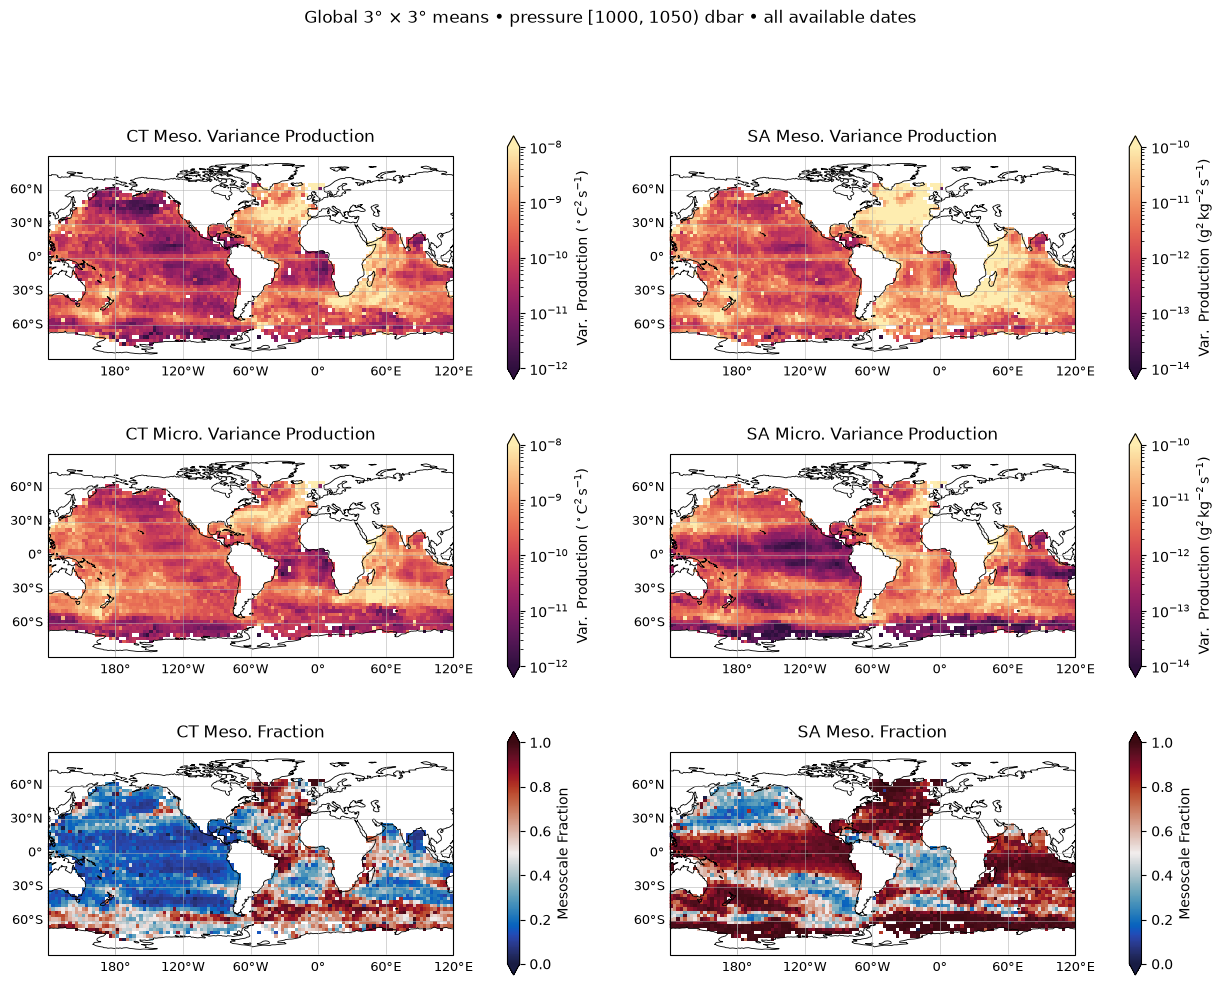

Pressure bin: [1000, 1050) dbar
Saved figure: /swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/figures/global_variance_pressure_1000_1050dbar.png


,Finite cells,Below 0,Above 1
Quantity,,,
Thermal fraction,3764,15,0
Salinity fraction,3764,5,0


In [2]:
from matplotlib import colors
import cartopy.crs as ccrs
import cmocean.cm as cmo

PRESSURE_TO_PLOT_DBAR = 1000.0
shrink, pad = 0.9, 0.1
pressure_bounds = global_pressure_means.pressure_bin_bounds.values
matches = np.flatnonzero((pressure_bounds[:, 0] <= PRESSURE_TO_PLOT_DBAR)
                        & (PRESSURE_TO_PLOT_DBAR < pressure_bounds[:, 1]))
if len(matches) != 1:
    raise ValueError("Requested pressure lies outside the saved pressure bins.")
level = global_pressure_means.isel(pressure_bin=int(matches[0]))
lower, upper = level.pressure_bin_bounds.values

def variance_fraction(dia, iso):
    total = dia + iso
    valid = np.isfinite(dia) & np.isfinite(iso) & np.isfinite(total) & (total > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (iso / total).where(valid)

thermal_isopycnal_fraction = variance_fraction(level.Pdia, level.Piso)
salinity_isopycnal_fraction = variance_fraction(level.PSdia, level.PSiso)
plot_data = level.assign(
    CT_meso_frac=thermal_isopycnal_fraction,
    SA_meso_frac=salinity_isopycnal_fraction,
)

# Columns: temperature, salinity. Rows: iso, dia, fraction.
ct_label = r"$\mathrm{Var.\ Production}\ ({}^\circ\mathrm{C}^{2}\,\mathrm{s}^{-1})$"
sa_label = r"$\mathrm{Var.\ Production}\ (\mathrm{g}^{2}\,\mathrm{kg}^{-2}\,\mathrm{s}^{-1})$"
fraction_label = r"$\mathrm{Mesoscale\ Fraction}$"
fields = [
    ("Piso", cmo.matter_r, (1e-12, 1e-8), "log", ct_label, "CT Meso. Variance Production"),
    ("PSiso", cmo.matter_r, (1e-14, 1e-10), "log", sa_label, "SA Meso. Variance Production"),
    ("Pdia", cmo.matter_r, (1e-12, 1e-8), "log", ct_label, "CT Micro. Variance Production"),
    ("PSdia", cmo.matter_r, (1e-14, 1e-10), "log", sa_label, "SA Micro. Variance Production"),
    ("CT_meso_frac", cmo.balance, (0, 1), "linear", fraction_label, "CT Meso. Fraction"),
    ("SA_meso_frac", cmo.balance, (0, 1), "linear", fraction_label, "SA Meso. Fraction"),
]

def plot_panel(ax, varname, cmap, vlims, norm_type, cbar_label, title):
    norm_class = colors.LogNorm if norm_type == "log" else colors.Normalize
    norm = norm_class(vmin=vlims[0], vmax=vlims[1])
    mesh = plot_data[varname].plot.pcolormesh(
        x="longitude", y="latitude", ax=ax,
        transform=ccrs.PlateCarree(), cmap=cmap, norm=norm,
        infer_intervals=True, add_labels=False,
        cbar_kwargs={"shrink": shrink, "pad": pad, "label": cbar_label, "extend": "both"},
    )
    if norm_type == "linear":
        mesh.colorbar.set_ticks(np.linspace(0, 1, 6))
    ax.set_global()
    ax.coastlines(resolution="110m", linewidth=0.6)
    grid = ax.gridlines(draw_labels=True, alpha=0.75, linewidth=0.5)
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {"size": 9}
    grid.ylabel_style = {"size": 9}
    # Explicit height avoids Cartopy moving titles into invisible grid labels.
    ax.set_title(title, y=1.03)

fig, axes = plt.subplots(
    3, 2, figsize=(15, 11.25),
    subplot_kw={"projection": ccrs.PlateCarree(central_longitude=-60)},
)
axes = axes.ravel()
for ax, field in zip(axes, fields):
    plot_panel(ax, *field)

plt.subplots_adjust(wspace=0.15, hspace=0.1)
fig.suptitle(f"Global 3° × 3° means • pressure [{lower:g}, {upper:g}) dbar • all available dates", y=0.98)

figure_dir = DATA_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / f"global_variance_pressure_{lower:g}_{upper:g}dbar.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Pressure bin: [{lower:g}, {upper:g}) dbar")
print(f"Saved figure: {figure_path}")

fraction_diagnostics = pd.DataFrame([
    {"Quantity": name, "Finite cells": int(values.notnull().sum()),
     "Below 0": int((values < 0).sum()), "Above 1": int((values > 1).sum())}
    for name, values in [("Thermal fraction", thermal_isopycnal_fraction),
                         ("Salinity fraction", salinity_isopycnal_fraction)]
]).set_index("Quantity")
display(fraction_diagnostics)


### Coverage and count checks for the saved averages

The embedded run report records a complete pass over the global manifest. These
checks verify the stored arrays against that report, including the salinity
terms. Neither grid is recomputed here.


In [4]:
# Full inventory and observation conservation, separately for both vertical grids.
assert global_bins_report["status"] == "complete"
assert global_bins_report["files_scanned"] == 25686
assert global_bins_report["profiles_scanned"] == 1117885
summary = {
    "Files read": global_bins_report["files_scanned"],
    "Profiles read": global_bins_report["profiles_scanned"],
    "Profiles with invalid position": global_bins_report["invalid_position_profiles"],
    "Saved Zfs observations": global_bins_report["saved_Zfs_observations"],
    "Pressure-coordinate observations": global_bins_report["valid_coordinate_observations"]["pressure_bin"],
    "Density-coordinate observations": global_bins_report["valid_coordinate_observations"]["neutral_density_bin"],
    "Computation seconds": round(global_bins_report["elapsed_seconds"], 1),
}
display(pd.Series(summary, name="Global binning audit").to_frame())
rows = []
for grid_name, binned in [("pressure_bin", global_pressure_means),
                           ("neutral_density_bin", global_density_means)]:
    for metric, result in global_bins_report["conservation"][grid_name].items():
        assert result["passed"]
        count = binned[metric + "_count"]
        assert int(count.sum()) == result["eligible_input_observations"]
        assert np.array_equal(np.isnan(binned[metric].values), count.values == 0)
        rows.append({"Grid": grid_name, "Metric": metric,
                     "Eligible observations": result["eligible_input_observations"],
                     "Binned observations": int(count.sum()),
                     "Populated bins": int((count > 0).sum()),
                     "PASS": True})
display(pd.DataFrame(rows).set_index(["Grid", "Metric"]))
print("PASS: all global files/profiles accounted for; every eligible observation assigned once per grid.")


,Global binning audit
Files read,25686.0
Profiles read,1117885.0
Profiles with invalid position,0.0
Saved Zfs observations,43597515.0
Pressure-coordinate observations,37742976.0
Density-coordinate observations,36577885.0
Computation seconds,107.6


Eligible observations  Binned observations  \
Grid                Metric                                                
pressure_bin        Krho                  30982455             30982455   
                    epsilon               30982455             30982455   
                    chi                   27820742             27820742   
                    Pdia                  27819217             27819217   
                    Piso                  27819172             27819172   
                    chiS                  27820742             27820742   
                    PSdia                 27819217             27819217   
                    PSiso                 27819172             27819172   
neutral_density_bin Krho                  30080768             30080768   
                    epsilon               30080768             30080768   
                    chi                   27820742             27820742   
                    Pdia                  27819217             27819217   
                    Piso                  27819172             27819172   
                    chiS                  27820742             27820742   
                    PSdia                 27819217             27819217   
                    PSiso                 27819172             27819172   

                             Populated bins  PASS  
Grid                Metric                         
pressure_bin        Krho             149306  True  
                    epsilon          149306  True  
                    chi              143302  True  
                    Pdia             143283  True  
                    Piso             143283  True  
                    chiS             143302  True  
                    PSdia            143283  True  
                    PSiso            143283  True  
neutral_density_bin Krho             217643  True  
                    epsilon          217643  True  
                    chi              217205  True  
                    Pdia             217193  True  
                    Piso             217193  True  
                    chiS             217205  True  
                    PSdia            217193  True  
                    PSiso            217193  True

PASS: all global files/profiles accounted for; every eligible observation assigned once per grid.


### Bitwise NATRE proof against the file Espe loaded

The candidate now comes from **`global_profiles.nc`**, rather than reopening the
25,686 partitions. Espe's original file is
`/swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc`,
as loaded in cell 5 (zero based) of `plots_mixing_NATRE_gamman_analysis.ipynb`.

Apply Espe's exact selection: 2014-01-01 ≤ time < 2024-01-01,
19° ≤ latitude < 32°, and −38° ≤ longitude < −20°.
Sort the candidate independently by time and signed WMO/cycle UID (Argopy
order); retain Espe's original order. Check the entire population, including
duplicate time/position occurrences, without intersecting away missing records.

Bitwise equality requires identical dimensions, shapes, dtypes and decoded array
bytes in logical C order, including NaN payloads and signed zeros, for all 34
reference data variables and three coordinates. NetCDF container bytes,
attributes and the 14 extra global identity/diagnostic variables are outside
that reference comparison. No tolerances or reference-based alignment are used.
Agreement in NATRE does not independently validate other global regions or the
original scientific assumptions.


In [5]:
# Explicit bounds match Espe's selection; read only this subset from one file.
mask = (
    (ds.time >= np.datetime64("2014-01-01"))
    & (ds.time < np.datetime64("2024-01-01"))
    & (ds.latitude >= 19)
    & (ds.latitude < 32)
    & (ds.longitude >= -38)
    & (ds.longitude < -20)
)
ds_NATRE = ds.isel(time=np.flatnonzero(mask.values)).load()
natre_global = canonical_order(ds_NATRE)

espe_path = Path("/swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc")
espe_notebook = json.loads((analysis_code_dir / "plots_mixing_NATRE_gamman_analysis.ipynb").read_text())
assert f'xr.open_dataset("{espe_path}")' in "".join(espe_notebook["cells"][5]["source"])
with xr.open_dataset(espe_path, engine="netcdf4") as original:
    natre_espe = original.load()
print("Global profile NetCDF:", profile_path)
print("Espe reference NetCDF:", espe_path)
print(f"Selected {ds_NATRE.sizes['time']:,} NATRE profiles from {ds.sizes['time']:,} global profiles.")


Global profile NetCDF: /swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_profiles.nc
Espe reference NetCDF: /swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc
Selected 6,261 NATRE profiles from 1,117,885 global profiles.


In [6]:
# Proof 1: entire population, duplicate multiplicities, order and annual counts.
coverage = coverage_proof(natre_global, natre_espe)
display(pd.Series(coverage, name="Coverage proof").to_frame())
annual_counts = pd.concat({
    "Global": pd.Series(natre_global.time.dt.year.values).value_counts(),
    "Espe": pd.Series(natre_espe.time.dt.year.values).value_counts(),
}, axis=1).fillna(0).astype(int).sort_index().rename_axis("Year")
annual_counts["Difference"] = annual_counts.Global - annual_counts.Espe
display(annual_counts)
assert bool(natre_mask(natre_global).all()) and bool(natre_mask(natre_espe).all())
assert coverage["same_population_with_multiplicity"], "Missing/extra NATRE profiles"
assert coverage["same_order_after_independent_sort"], "Profile order differs"
assert natre_global.sizes["time"] == natre_espe.sizes["time"] == 6261
assert (annual_counts.Difference == 0).all()
print("PASS: all 6,261 profiles, including duplicate occurrences; no missing or extra records.")


,Coverage proof
global_profiles,6261
espe_profiles,6261
missing_profiles,0
extra_profiles,0
global_duplicate_keys,1
espe_duplicate_keys,1
same_population_with_multiplicity,True
same_order_after_independent_sort,True


,Global,Espe,Difference
Year,,,
2014,916,916,0
2015,1213,1213,0
2016,750,750,0
2017,384,384,0
2018,407,407,0
2019,572,572,0
2020,457,457,0
2021,411,411,0
2022,583,583,0


PASS: all 6,261 profiles, including duplicate occurrences; no missing or extra records.


In [7]:
# Proof 2: direct bytes, not allclose/equal_nan or matching hashes alone.
array_checks = array_proof(natre_global, natre_espe)
extra_global_variables = sorted(set(natre_global.data_vars) - set(natre_espe.data_vars))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(array_checks[["dims", "shape", "espe_dtype", "global_dtype",
                          "same_dims_shape_dtype", "different_elements_bits", "bitwise_equal"]])
    display(array_checks[["global_sha256", "espe_sha256"]])
print("Additional global identity/diagnostic variables:", extra_global_variables)
assert len(natre_espe.data_vars) == 34 and len(natre_espe.coords) == 3
assert len(array_checks) == 37 and array_checks.bitwise_equal.all(), "BITWISE COMPARISON FAILED"
assert (array_checks.different_elements_bits == 0).all()
print("PASS: 34/34 data variables + 3/3 coordinates are bitwise identical; zero differing elements.")


,dims,shape,espe_dtype,global_dtype,same_dims_shape_dtype,different_elements_bits,bitwise_equal
variable,,,,,,,
CT,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
CT_fs,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
CT_poly,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
Krho,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
MLD,"('time',)","(6261,)",<f8,<f8,True,0,True
N2,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
N_data_fs,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
Pdia,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
PdiaS,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True


,global_sha256,espe_sha256
variable,,
CT,2b0b69f76ccace5b88c9ddf0d859b546cdc04ae5a528dbf0dc11bcc57f078dad,2b0b69f76ccace5b88c9ddf0d859b546cdc04ae5a528dbf0dc11bcc57f078dad
CT_fs,ec5b237b1b1224271b0db93244fd86eca870a32772fa87973af17437de5fe380,ec5b237b1b1224271b0db93244fd86eca870a32772fa87973af17437de5fe380
CT_poly,9b48861130cccfa5d9fca20b635516df196a773a36510750af03a99fda863068,9b48861130cccfa5d9fca20b635516df196a773a36510750af03a99fda863068
Krho,4f28550a7000da1cfcdc17a0f207e844287993845a6aeba1451f4ff7d70e74a0,4f28550a7000da1cfcdc17a0f207e844287993845a6aeba1451f4ff7d70e74a0
MLD,6d2e5914e5b8c667655a6f5a5fdf20f5e0155dfa8a4c9d9f4d11c556d8de4798,6d2e5914e5b8c667655a6f5a5fdf20f5e0155dfa8a4c9d9f4d11c556d8de4798
N2,417bfa322dc56e2a4c772bfe2f74c442f5dae68329f071fd691cbdc332da9211,417bfa322dc56e2a4c772bfe2f74c442f5dae68329f071fd691cbdc332da9211
N_data_fs,5669b5d6908dd2513e89c70925a9198cd7e3619480d02182f2119559a3ca1f8e,5669b5d6908dd2513e89c70925a9198cd7e3619480d02182f2119559a3ca1f8e
Pdia,94d8664e0aba81255185830c2d039f62519ff806360dc5ab84a17e2d9d098e0f,94d8664e0aba81255185830c2d039f62519ff806360dc5ab84a17e2d9d098e0f
PdiaS,82c87ca43d734f075366b6f9e0f9c74bc93bbc7972aed722b1da493da5d2965d,82c87ca43d734f075366b6f9e0f9c74bc93bbc7972aed722b1da493da5d2965d


Additional global identity/diagnostic variables: ['cycle_number', 'direction', 'gamma_n_failed_sample_count', 'gamma_n_status', 'input_profile_index', 'mean_pressure_spacing_upper_1000', 'mixsea_status', 'n2_status', 'platform_number', 'polynomial_status', 'position_valid', 'profile_id', 'source_file', 'stage_message']
PASS: 34/34 data variables + 3/3 coordinates are bitwise identical; zero differing elements.


In [8]:
# Proof 3: negative controls show this really distinguishes bits and coverage.
def tiny(values):
    return xr.Dataset({"value": ("sample", values)})

assert not array_proof(tiny(np.array([0.0])), tiny(np.array([-0.0]))).bitwise_equal.all()
nan_a = np.array([0x7ff8000000000001], dtype=np.uint64).view(np.float64)
nan_b = np.array([0x7ff8000000000002], dtype=np.uint64).view(np.float64)
assert np.isnan(nan_a[0]) and np.isnan(nan_b[0])
assert not array_proof(tiny(nan_a), tiny(nan_b)).bitwise_equal.all()
assert not array_proof(tiny(np.array([1.0], dtype="float32")),
                       tiny(np.array([1.0], dtype="float64"))).bitwise_equal.all()
identity = natre_espe[["longitude", "latitude"]]
missing_control = coverage_proof(identity.isel(time=slice(1, None)), identity)
extra_control = coverage_proof(xr.concat([identity, identity.isel(time=[0])], dim="time"), identity)
assert missing_control["missing_profiles"] == 1 and not missing_control["same_population_with_multiplicity"]
assert extra_control["extra_profiles"] == 1 and not extra_control["same_population_with_multiplicity"]
print("PASS: signed-zero, NaN-payload, dtype, missing-profile and extra-duplicate changes all fail.")


PASS: signed-zero, NaN-payload, dtype, missing-profile and extra-duplicate changes all fail.


## Average profiles (no bootstrap uncertainty)

Compute each dataset's means **independently**, in the same profile order, directly
on the saved `Zfs` grid. Each depth has equal weight per non-NaN profile.
`Krho` and `Pdia` are saved profile variables; define **Piso = chi − Pdia per
profile before averaging**, so its mean uses paired valid observations. Keep
negative residuals (shown on a symmetric-log axis); apply no extra outlier mask,
clipping, interpolation, bootstrap or confidence interval.

These are descriptive depth-wise averages of the loaded profile data, not the
density/time-window bootstrap estimates from Espe's regional summary. The table
below checks both the resulting means and their contributing counts bitwise.


In [9]:
global_means = mean_profiles(natre_global)
espe_means = mean_profiles(natre_espe)
mean_checks = array_proof(global_means, espe_means)
display(mean_checks[["same_dims_shape_dtype", "different_elements_bits", "bitwise_equal"]])
assert mean_checks.bitwise_equal.all(), "Average profiles or counts differ bitwise"
print("PASS: independently computed average profiles and contributing counts are also bitwise identical.")


,same_dims_shape_dtype,different_elements_bits,bitwise_equal
variable,,,
Krho,True,0,True
Krho_count,True,0,True
Pdia,True,0,True
Pdia_count,True,0,True
Piso,True,0,True
Piso_count,True,0,True
Zfs,True,0,True


PASS: independently computed average profiles and contributing counts are also bitwise identical.


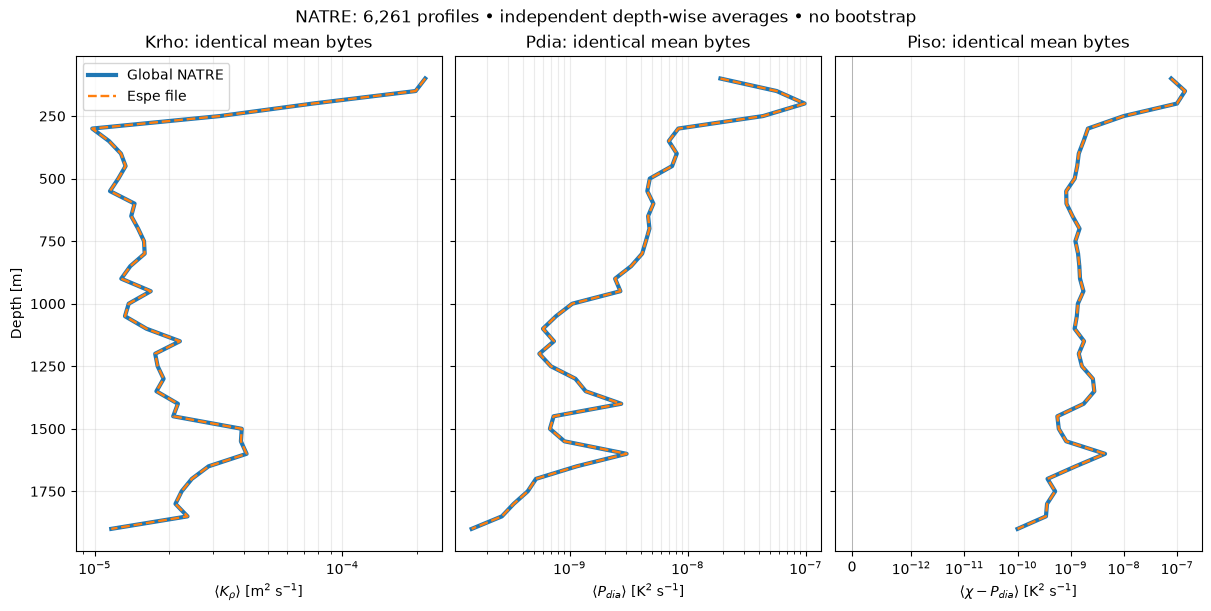

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True, constrained_layout=True)
for ax, name, label in zip(
    axes, ["Krho", "Pdia", "Piso"],
    [r"$\langle K_\rho\rangle$ [m$^2$ s$^{-1}$]",
     r"$\langle P_{dia}\rangle$ [K$^2$ s$^{-1}$]",
     r"$\langle \chi-P_{dia}\rangle$ [K$^2$ s$^{-1}$]"],
):
    ax.plot(global_means[name], global_means.Zfs, color="tab:blue", lw=3,
            label="Global NATRE")
    ax.plot(espe_means[name], espe_means.Zfs, color="tab:orange", ls="--", lw=1.7,
            label="Espe file")
    if name == "Piso":
        ax.set_xscale("symlog", linthresh=1e-12)
        ax.axvline(0, color="0.7", lw=0.7)
    else:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.grid(alpha=0.25, which="both")
    ax.set_title(name + ": identical mean bytes")
axes[0].set_ylabel("Depth [m]")
axes[0].invert_yaxis()
axes[0].legend()
fig.suptitle("NATRE: 6,261 profiles • independent depth-wise averages • no bootstrap")
plt.show()


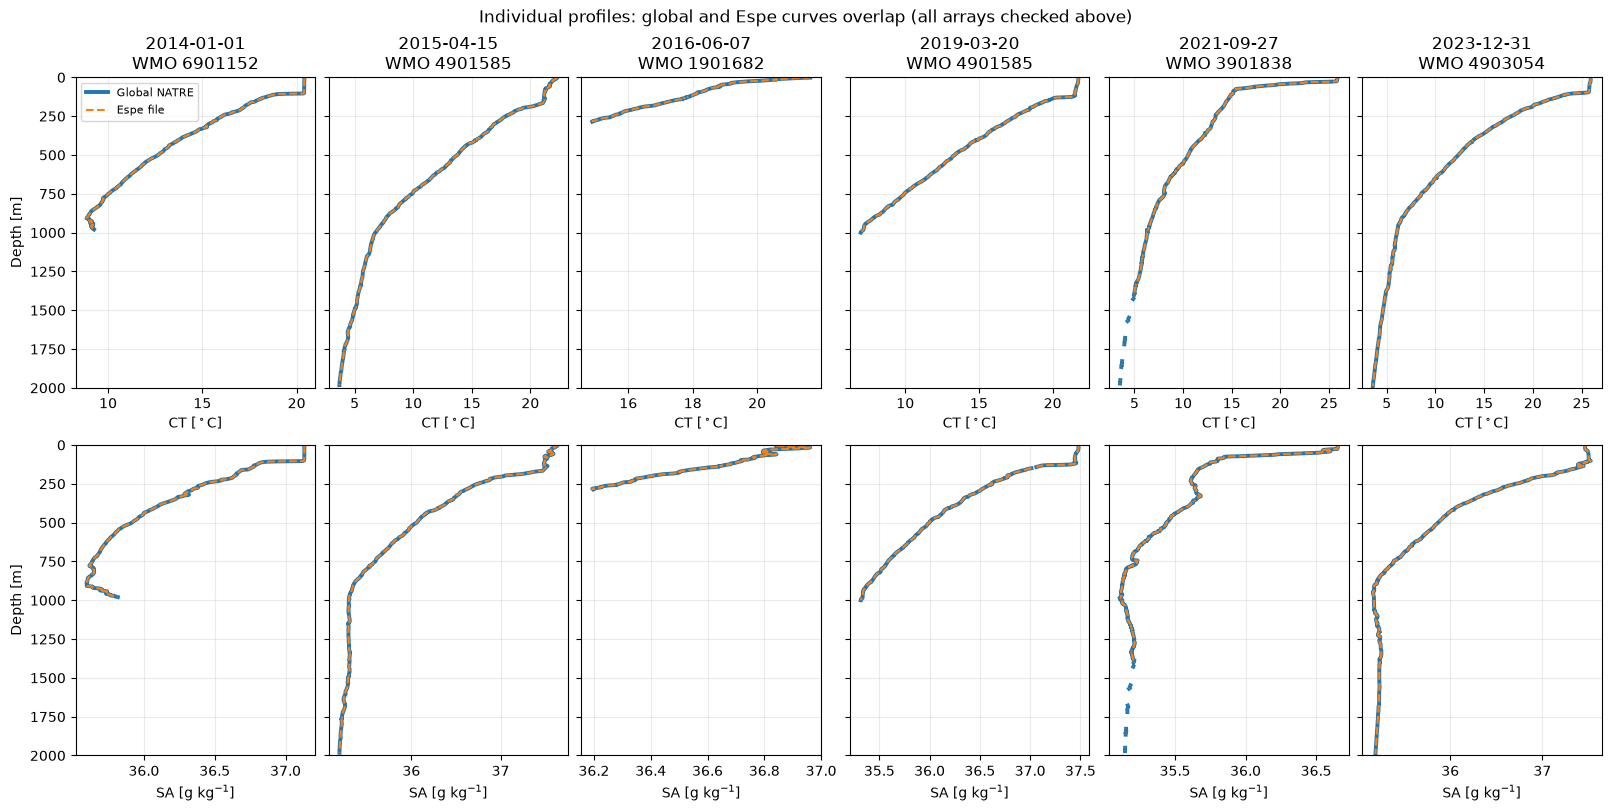

In [11]:
# Additional visual check: six profiles spanning the reference period.
# Indices depend only on the candidate length, not on an agreement search.
example_indices = np.linspace(0, natre_global.sizes["time"] - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 6, figsize=(16, 8), sharey=True, constrained_layout=True)
for col, index in enumerate(example_indices):
    a, b = natre_global.isel(time=index), natre_espe.isel(time=index)
    for row, name, label in [(0, "CT", r"CT [$^\circ$C]"), (1, "SA", r"SA [g kg$^{-1}$]")]:
        ax = axes[row, col]
        ax.plot(a[name], a.Z, color="tab:blue", lw=2.8, label="Global NATRE")
        ax.plot(b[name], b.Z, color="tab:orange", ls="--", lw=1.5, label="Espe file")
        ax.set_xlabel(label)
        ax.grid(alpha=0.25)
    axes[0, col].set_title(str(a.time.values)[:10] + chr(10) + "WMO " + str(int(a.platform_number.values)))
axes[0, 0].set_ylim(2000, 0)
axes[0, 0].set_ylabel("Depth [m]")
axes[1, 0].set_ylabel("Depth [m]")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Individual profiles: global and Espe curves overlap (all arrays checked above)")
plt.show()


In [12]:
assert coverage["same_population_with_multiplicity"] and coverage["same_order_after_independent_sort"]
assert array_checks.bitwise_equal.all() and mean_checks.bitwise_equal.all()
display(Markdown(
    "**PASS — 6,261/6,261 NATRE profiles; zero missing or extra profiles; "
    "34/34 reference data variables and 3/3 coordinates are bitwise identical.** "
    "The independently computed average Krho, Pdia and Piso profiles and counts "
    "also match bitwise. This verdict covers decoded reference arrays after "
    "independent profile ordering, not whole NetCDF files or the 14 extra global diagnostics."
))


**PASS — 6,261/6,261 NATRE profiles; zero missing or extra profiles; 34/34 reference data variables and 3/3 coordinates are bitwise identical.** The independently computed average Krho, Pdia and Piso profiles and counts also match bitwise. This verdict covers decoded reference arrays after independent profile ordering, not whole NetCDF files or the 14 extra global diagnostics.